## Example ERA5 calculation

In [3]:
import warnings

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xa
from localoverturning import compute_overturning

warnings.simplefilter(action="ignore", category=FutureWarning)
era5_path = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
full_era5 = xa.open_zarr(era5_path, chunks=None, storage_options=dict(token="anon"))

In [4]:
example_omega = full_era5.vertical_velocity.sel(time="2018-02-25 18:00", level=400)
ot_ds = compute_overturning(example_omega, truncs=21)

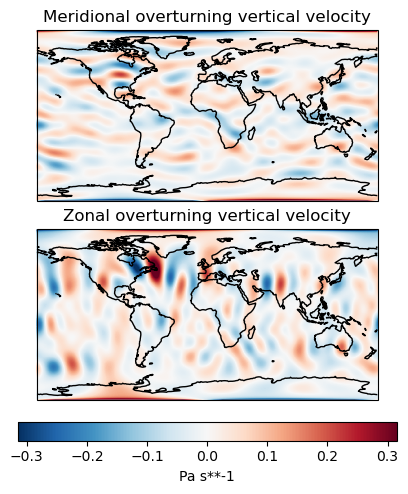

In [5]:
fields = [
    ot_ds.meridional_overturning_vertical_velocity,
    ot_ds.zonal_overturning_vertical_velocity,
]

vmax = np.nanpercentile(
    ot_ds.zonal_overturning_vertical_velocity,
    99.5,
)

fig, axes = plt.subplots(
    2,
    1,
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

for ax, field, title in zip(
    axes,
    fields,
    ["Meridional overturning vertical velocity", "Zonal overturning vertical velocity"],
):
    mesh = ax.pcolormesh(
        field.longitude,
        field.latitude,
        field,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto",
    )
    ax.set_global()
    ax.coastlines()
    ax.set_title(title)

fig.colorbar(
    mesh,
    ax=axes,
    orientation="horizontal",
    shrink=0.6,
    label=fields[0].attrs.get("units", ""),
)
plt.show()

In [ ]:
from localoverturning import mass_flux

otmf_ds = mass_flux(ot_ds)

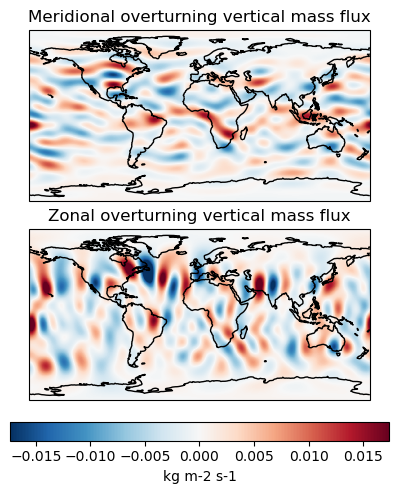

In [8]:
fields = [
    otmf_ds.meridional_overturning_vertical_mass_flux,
    otmf_ds.zonal_overturning_vertical_mass_flux,
]

vmax = np.nanpercentile(
    otmf_ds.zonal_overturning_vertical_mass_flux,
    99.5,
)

fig, axes = plt.subplots(
    2,
    1,
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

for ax, field, title in zip(
    axes,
    fields,
    ["Meridional overturning vertical mass flux", "Zonal overturning vertical mass flux"],
):
    mesh = ax.pcolormesh(
        field.longitude,
        field.latitude,
        field,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto",
    )
    ax.set_global()
    ax.coastlines()
    ax.set_title(title)

fig.colorbar(
    mesh,
    ax=axes,
    orientation="horizontal",
    shrink=0.6,
    label=fields[0].attrs.get("units", ""),
)
plt.show()